# Force velocity — dF/dt

The arrival-time measures ask *when each finger reached its target*, which conflates two
things: whether the fingers were driven together, and whether they landed together. A pair
can be launched simultaneously and still arrive far apart if one of them overshoots, drifts,
or takes a second attempt to settle inside the zone.

The derivative of the force separates those. `dF/dt` shows when each finger was actually
being *moved*, regardless of whether it was on target at the time.

These are plain plots — no arrival markers, no within or between latencies. Same layout as
the force figures: one random trial per block, blocks down the rows, session across the
columns, one file per chord in `figures/s<sn>/example_trials/`.

The force in the `.pkl` is already low-passed at 12.5 Hz, so it is differentiated directly
with `np.gradient`; no extra smoothing is applied.

Correct trials are drawn first. If a session has fewer correct trials than rows (e.g. a
chord the subject could not produce at all in Test 1), the rest are filled with
unsuccessful trials, tinted red and tagged `UNSUCCESSFUL` with how they failed, and the
session header says how many of the shown trials failed. Plan errors are never used.
Unsuccessful trials run to the 10 s time-out, so each session has its own time axis.

## Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

ROOT = Path.cwd()
while not (ROOT / "target").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

SN = 101
SEED = 1517            # <<< int for reproducible trial picks, None for fresh ones
YLIM = 40           # <<< symmetric y limit in force units / s
FS = 500            # Hz, sampling rate of the .mov
DT = 1.0 / FS

from utils.design import TEST1_BLOCKS, TEST2_BLOCKS, TRAIN_BLOCKS, TRAIN_EARLY, TRAIN_LATE
from utils.examples import mark_unsuccessful, panel_title, sample, session_label

ANALYSIS_DIR = ROOT / "analysis"
EX_DIR = ROOT / "figures" / f"s{SN}" / "example_trials"
EX_DIR.mkdir(parents=True, exist_ok=True)

WAIT_EXEC = 3
PRE_BLOCKS, POST_BLOCKS = list(TEST1_BLOCKS), list(TEST2_BLOCKS)
FINGERS = ["thumb", "index", "middle", "ring", "pinky"]
STATE_OF = {"1": "ext", "2": "flex", "9": "rel"}

sns.set_theme(style="ticks", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})
PAL = dict(zip(FINGERS, sns.color_palette("colorblind", 5)))

df = pd.read_csv(ANALYSIS_DIR / f"s{SN}.csv")
mov = pd.read_pickle(ANALYSIS_DIR / f"s{SN}_mov.pkl")
REC = {(r.BN, r.TN): r for r in mov.itertuples()}
rng = np.random.default_rng(SEED)

TRAINED = sorted(df.loc[df.BN.isin(TRAIN_BLOCKS), "chordID"].unique().tolist())
TESTED = sorted(df.loc[df.BN.isin(PRE_BLOCKS), "chordID"].unique().tolist())
PAIR_A, PAIR_B = (0, 1), (3, 4)          # the two component finger slots
COMPONENT = {tuple(i for i, d in enumerate(str(c)) if d != "9"): c for c in TRAINED}

print(f"s{SN}: tested {TESTED}, trained {TRAINED}")

s101: tested [12912, 12921, 21912, 21921], trained [12999, 99912]


## Figures

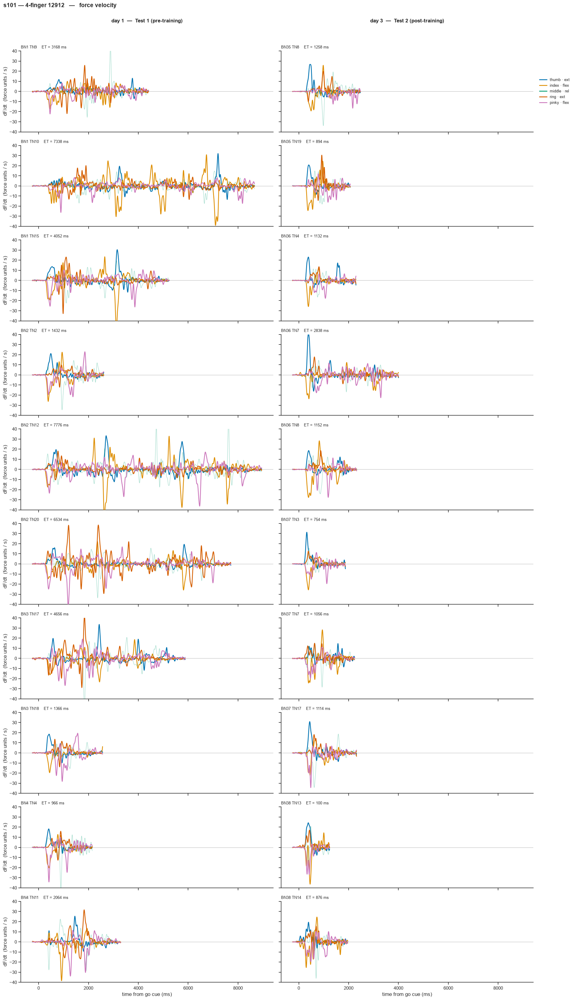

wrote figures/s101/example_trials/velocity_12912.png


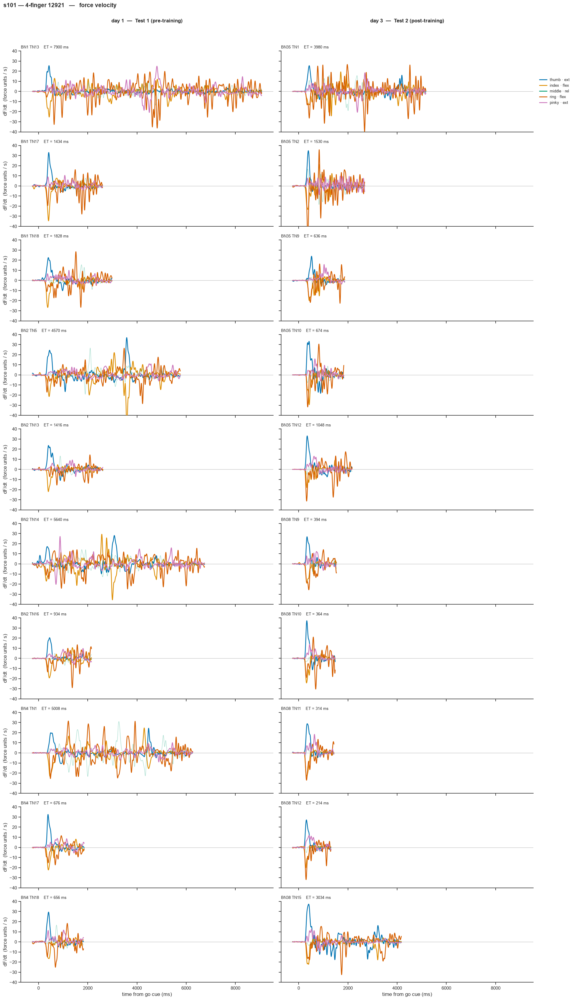

wrote figures/s101/example_trials/velocity_12921.png


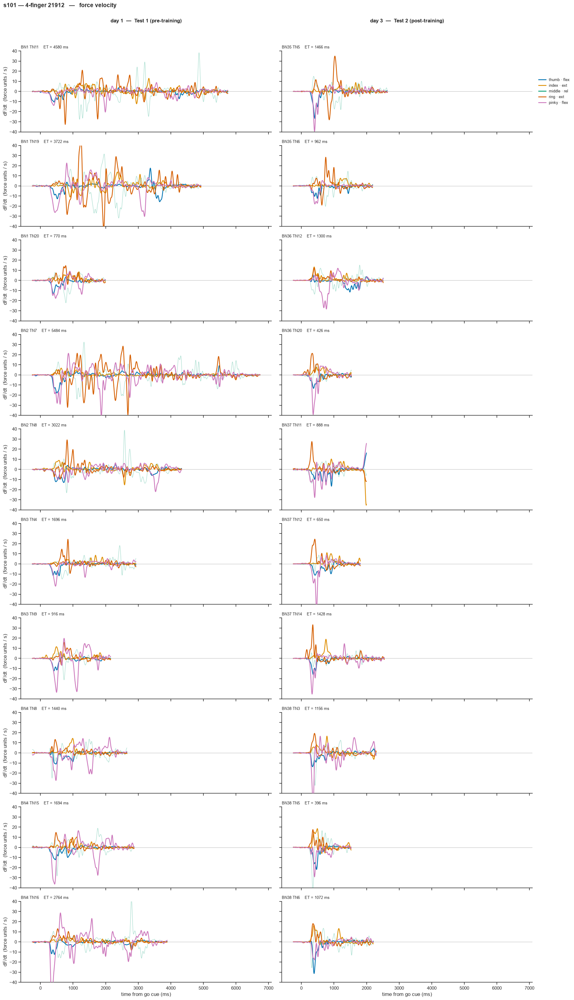

wrote figures/s101/example_trials/velocity_21912.png


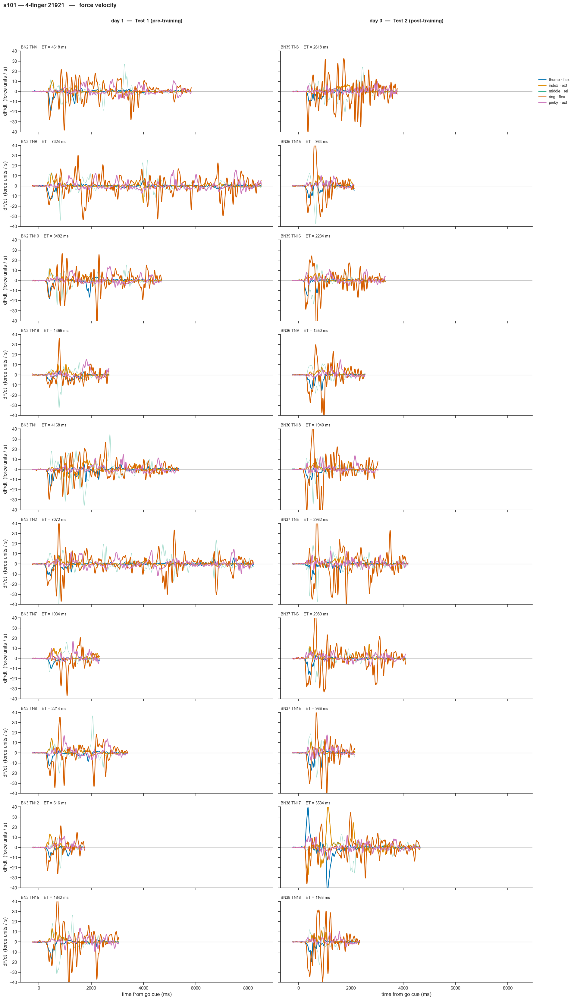

wrote figures/s101/example_trials/velocity_21921.png


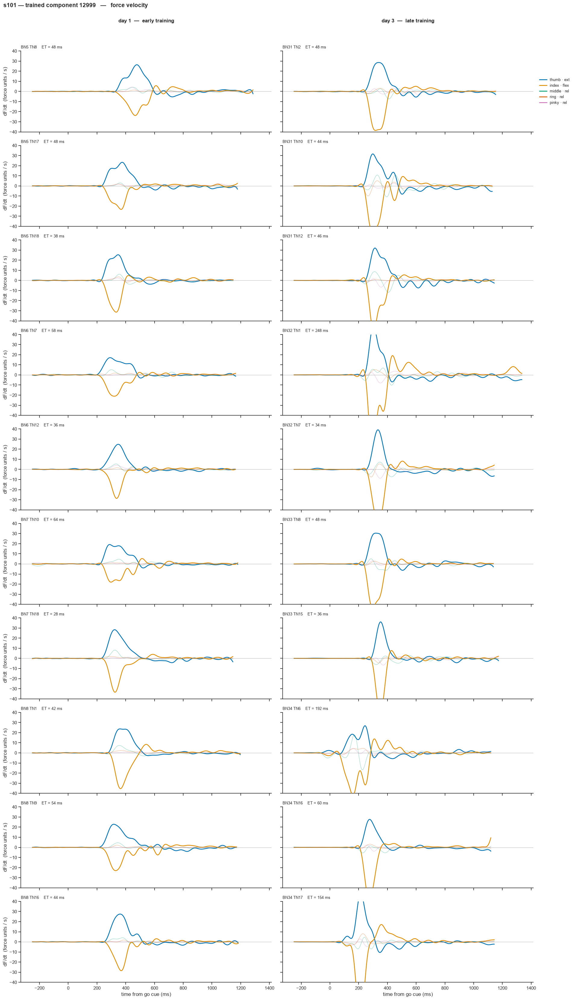

wrote figures/s101/example_trials/velocity_component_12999.png


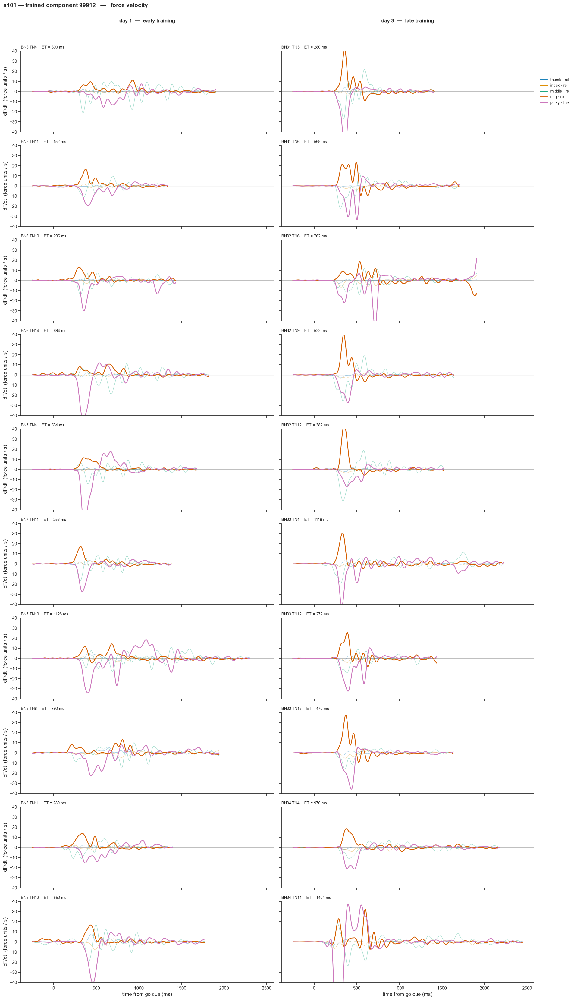

wrote figures/s101/example_trials/velocity_component_99912.png


In [2]:
N_TRIALS = 10        # <<< random trials to show per session

SESSIONS = [("day 1  \u2014  Test 1 (pre-training)", PRE_BLOCKS),
            ("day 3  \u2014  Test 2 (post-training)", POST_BLOCKS)]
TRAIN_SESSIONS = [("day 1  \u2014  early training", TRAIN_EARLY),
                  ("day 3  \u2014  late training", TRAIN_LATE)]

targets = [(c, SESSIONS, f"velocity_{c}.png", "4-finger") for c in TESTED]
targets += [(c, TRAIN_SESSIONS, f"velocity_component_{c}.png", "trained component")
            for c in TRAINED]

for chord_id, sessions, fname, kind in targets:
    chord = str(chord_id)
    picks = {lab: sample(df, chord_id, blocks, N_TRIALS, rng)
             for lab, blocks in sessions}
    nrow = max(len(v) for v in picks.values()) or 1
    fig, axes = plt.subplots(nrow, len(sessions), figsize=(9.6 * len(sessions), 3.3 * nrow),
                             sharex="col", sharey=True, squeeze=False)

    for col, (label, _) in enumerate(sessions):
        rows = picks[label]
        for row in range(nrow):
            ax = axes[row][col]
            if row >= len(rows):
                ax.set_axis_off()
                continue
            tr = rows[row]
            rec = REC[(int(tr.BN), int(tr.TN))]
            t0 = rec.t[rec.state == WAIT_EXEC][0]
            tt = rec.t - t0                              # time from the go cue
            exi = np.where(rec.state == WAIT_EXEC)[0]
            m = (tt >= -250) & (tt <= tt[exi[-1]] + 200)
            vel = np.gradient(rec.force, DT, axis=0)     # force units per second

            ax.axhline(0, color="0.75", lw=.9, zorder=1)
            for k in range(5):
                ax.plot(tt[m], vel[m, k], color=PAL[FINGERS[k]],
                        lw=1.9 if chord[k] != "9" else 1.0,
                        alpha=1.0 if chord[k] != "9" else .35,
                        label=f"{FINGERS[k]} · {STATE_OF[chord[k]]}", zorder=3)
            ax.set_title(panel_title(tr), fontsize=9.5, loc="left")
            mark_unsuccessful(ax, tr)
            ax.set_ylim(-YLIM, YLIM)
            if col == 0:
                ax.set_ylabel("dF/dt  (force units / s)")
        axes[0][col].annotate(session_label(label, rows), xy=(.5, 1.34),
                              xycoords="axes fraction",
                              ha="center", va="bottom", fontsize=12, fontweight="bold")
        if rows:
            axes[len(rows) - 1][col].set_xlabel("time from go cue (ms)")

    handles = [Line2D([], [], color=PAL[FINGERS[k]], lw=2,
                      label=f"{FINGERS[k]} · {STATE_OF[chord[k]]}") for k in range(5)]
    axes[0][-1].legend(handles=handles, frameon=False, loc="center left",
                       bbox_to_anchor=(1.01, .5), fontsize=9)
    fig.suptitle(f"s{SN} \u2014 {kind} {chord_id}   \u2014   force velocity",
                 fontsize=14, x=.01, ha="left", fontweight="bold", y=1.005)
    sns.despine(fig=fig)
    plt.tight_layout()
    plt.savefig(EX_DIR / fname, dpi=175, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"wrote {EX_DIR.relative_to(ROOT)}/{fname}")

## Components isolated

The same trials again, each 4-finger chord split into its two component finger slots and
drawn separately. `SEED` is reset first, so these are the same trials as the full-chord
velocity figures above.

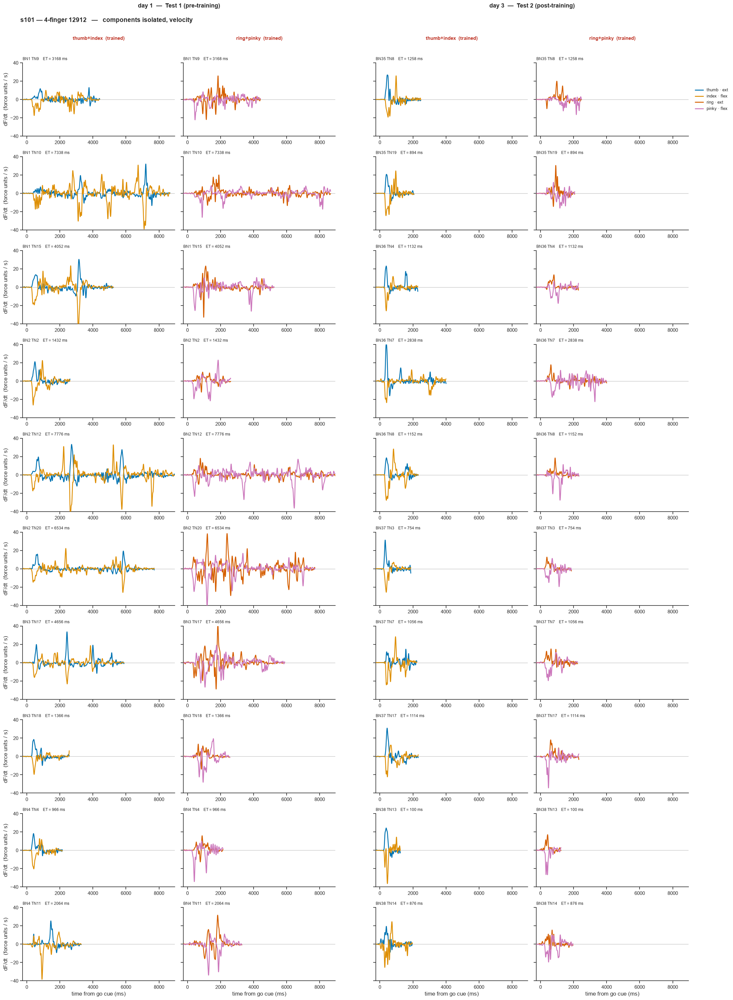

wrote figures/s101/example_trials/velocity_pairs_12912.png


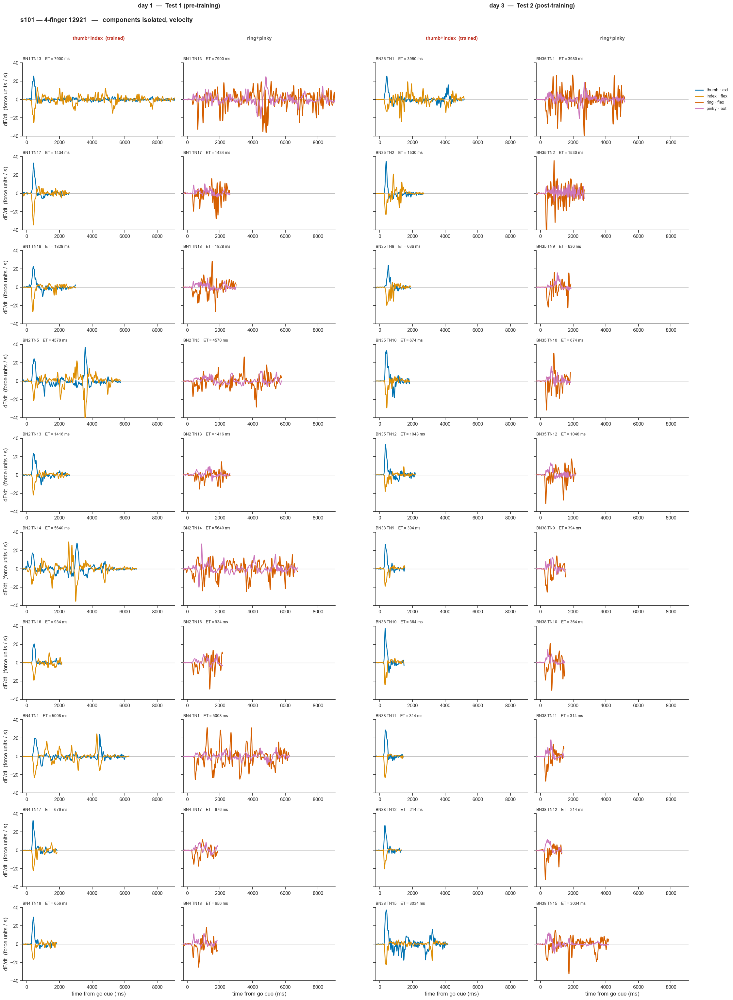

wrote figures/s101/example_trials/velocity_pairs_12921.png


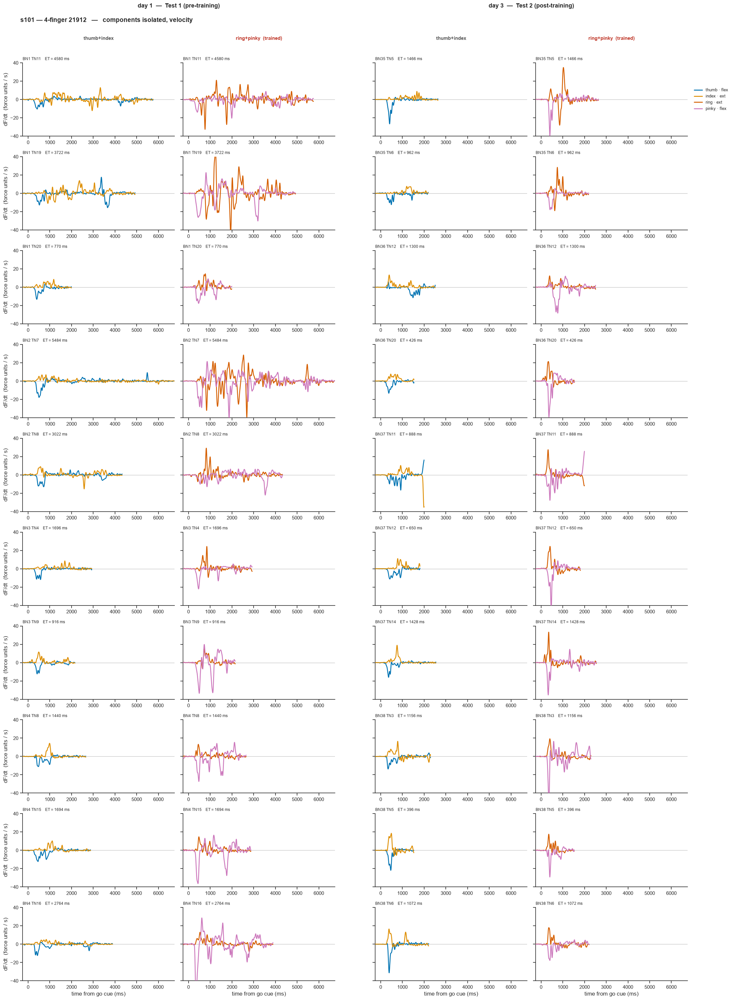

wrote figures/s101/example_trials/velocity_pairs_21912.png


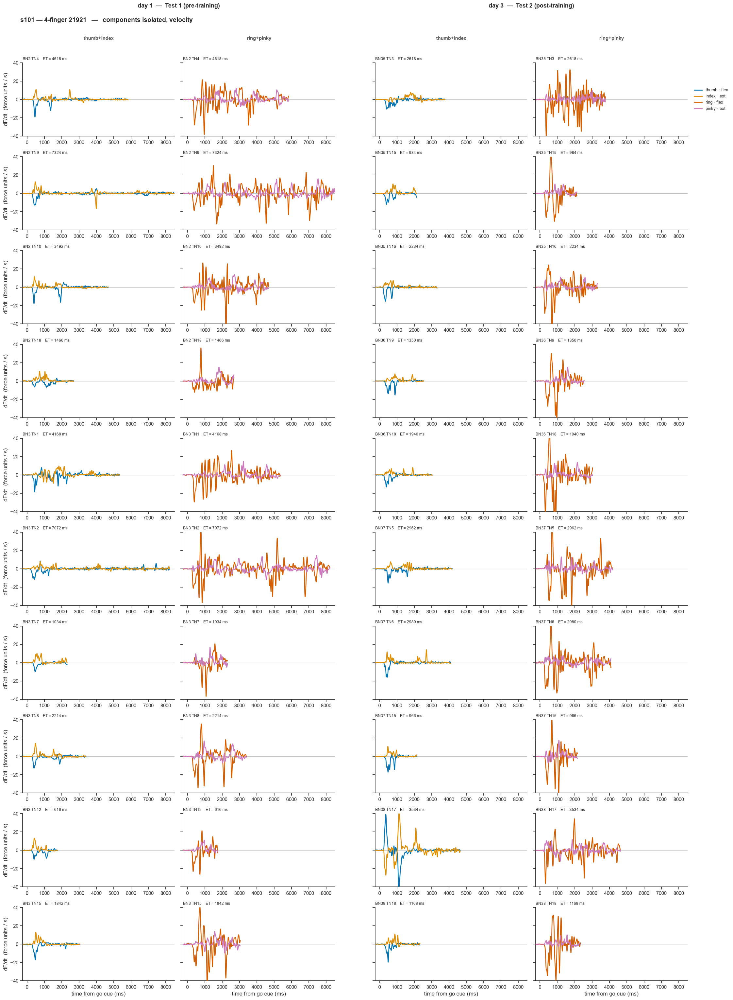

wrote figures/s101/example_trials/velocity_pairs_21921.png


In [3]:
PAIRS = [(PAIR_A, "thumb+index"), (PAIR_B, "ring+pinky")]
rng = np.random.default_rng(SEED)        # same draw as the full-chord figures above

for chord_id in TESTED:
    chord = str(chord_id)
    picks = {lab: sample(df, chord_id, blocks, N_TRIALS, rng)
             for lab, blocks in SESSIONS}
    nrow = max(len(v) for v in picks.values()) or 1
    ncol = len(SESSIONS) * len(PAIRS)
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.4 * ncol, 3.0 * nrow),
                             sharey=True, squeeze=False)
    xmax = {}                                # per session: failed trials run to 10 s

    for si, (label, _) in enumerate(SESSIONS):
        rows = picks[label]
        for row in range(nrow):
            for pi, (pair, pname) in enumerate(PAIRS):
                ax = axes[row][si * len(PAIRS) + pi]
                if row >= len(rows):
                    ax.set_axis_off()
                    continue
                tr = rows[row]
                rec = REC[(int(tr.BN), int(tr.TN))]
                t0 = rec.t[rec.state == WAIT_EXEC][0]
                tt = rec.t - t0
                exi = np.where(rec.state == WAIT_EXEC)[0]
                hi = tt[exi[-1]] + 200
                m = (tt >= -250) & (tt <= hi)
                xmax[si] = max(xmax.get(si, 0), hi)
                vel = np.gradient(rec.force, DT, axis=0)

                ax.axhline(0, color="0.75", lw=.9, zorder=1)
                for k in pair:
                    ax.plot(tt[m], vel[m, k], color=PAL[FINGERS[k]], lw=1.9, zorder=3)
                ax.set_title(panel_title(tr), fontsize=8.5, loc="left")
                mark_unsuccessful(ax, tr, fontsize=7.5)
                ax.set_ylim(-YLIM, YLIM)
                if si == 0 and pi == 0:
                    ax.set_ylabel("dF/dt  (force units / s)")

    for si in range(len(SESSIONS)):
        for pi in range(len(PAIRS)):
            col = si * len(PAIRS) + pi
            for row in range(nrow):
                if axes[row][col].axison:
                    axes[row][col].set_xlim(-250, xmax.get(si, 1000))
            last = max((r for r in range(nrow) if axes[r][col].axison), default=None)
            if last is not None:
                axes[last][col].set_xlabel("time from go cue (ms)")
            slot = PAIRS[pi][0]
            trained = slot in COMPONENT and all(chord[i] == str(COMPONENT[slot])[i]
                                                for i in slot)
            axes[0][col].annotate(PAIRS[pi][1] + ("  (trained)" if trained else ""),
                                  xy=(.5, 1.30), xycoords="axes fraction", ha="center",
                                  va="bottom", fontsize=10.5, fontweight="bold",
                                  color="#c0392b" if trained else "0.35")

    handles = [Line2D([], [], color=PAL[FINGERS[k]], lw=2,
                      label=f"{FINGERS[k]} · {STATE_OF[chord[k]]}")
               for k in list(PAIR_A) + list(PAIR_B)]
    axes[0][-1].legend(handles=handles, frameon=False, loc="center left",
                       bbox_to_anchor=(1.02, .5), fontsize=9)
    fig.suptitle(f"s{SN} \u2014 4-finger {chord_id}   \u2014   components isolated, velocity",
                 fontsize=14, x=.01, ha="left", fontweight="bold", y=1.004)
    sns.despine(fig=fig)
    plt.tight_layout()

    SESSION_GAP = 0.045                      # <<< figure fraction
    for row in range(nrow):
        for col in range(ncol):
            ax = axes[row][col]
            if not ax.axison:
                continue
            shift = -SESSION_GAP / 2 if col < len(PAIRS) else SESSION_GAP / 2
            b = ax.get_position()
            ax.set_position([b.x0 + shift, b.y0, b.width, b.height])

    fig.canvas.draw()
    for si, (label, _) in enumerate(SESSIONS):
        b0 = axes[0][si * len(PAIRS)].get_position()
        b1 = axes[0][si * len(PAIRS) + len(PAIRS) - 1].get_position()
        fig.text((b0.x0 + b1.x1) / 2, b0.y1 + .055, session_label(label, picks[label]),
                 ha="center", va="bottom", fontsize=13, fontweight="bold")

    plt.savefig(EX_DIR / f"velocity_pairs_{chord_id}.png", dpi=175,
                bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"wrote {EX_DIR.relative_to(ROOT)}/velocity_pairs_{chord_id}.png")